# 05 · Tensile-test analysis of ten S355 specimens: overview

**Goal.** Run the complete analysis of all ten tensile tests from the hosted research graphs, once from their PMDco 2 description and once from their PMDco 3 description, and show the results: properties per specimen, statistics per orientation, the comparison with the lab's values, and two overview figures.

**Audience.** All readers; the entry point for materials scientists and engineers (MSE experts).

**Prerequisites.** The terms of the tensile test (ISO 6892-1: E, ReH, ReL, Rp0.2, Fm, Rm, Ag, Agt, A, Z). No RDF or workflow knowledge is needed. The `pmd-demonstrator` environment from `environment.yml`, which installs the package `pmd_tensile`, and `ONTODOCKER_ADDRESS` (and `ONTODOCKER_TOKEN`, if the instance needs one) set in the environment before Jupyter starts. Neither is printed here.

**Reading paths.** MSE experts: **05** → 02 → 01. Ontologists: 01 → 04 → **05**. Workflow developers: 03 → 04 → 02 → **05**.

| Notebook | Details on |
| --- | --- |
| [01 · The tensile tests as data](01-tensile-data-from-graphs.ipynb) | the PMDco 2 and PMDco 3 graphs, ontology profiles, the neutral records, the Dataportal records |
| [02 · Tensile-test analysis, node by node](02-tensile-analysis-nodes.ipynb) | what each analysis step computes and where it fails, on Zx3, Zy3 and Zd3 |
| [03 · Building the workflow](03-tensile-workflow-building.ipynb) | how the nodes form the per-specimen workflow and the batch, and how to change a method parameter |
| [04 · The workflow as a knowledge graph](04-tensile-workflow-knowledge-graph.ipynb) | what semantikon records about a run, validation, and a query across run and data graph |

All properties are **method-defined, ISO 6892-1-inspired** (method specification v2.6). Nothing here claims conformity with ISO 6892-1 or its Annex G.

*Execution class: network-read.* SPARQL queries to Ontodocker and the download of ten curve files from the public data host, once per ontology generation. Nothing is written to remote services or to disk.

## 1. Description and analysis

The research graphs say *what* was measured: which specimen was tested, its cross-section and gauge length, which CSV file holds its curve, which column is the force and in which unit. The analysis needs numbers and arrays in known units, not the concepts. The workflow therefore has a boundary:

```
graph (PMDco 2 or PMDco 3) --exploration--> specimen IDs
                           --acquisition--> neutral records --analysis--> properties, flags, uncertainty components
```

- **Exploration** and **acquisition** are the only steps that know an ontology. An *ontology profile*, selected by the workflow input `profile_id`, holds the ontology-specific SPARQL queries and unit conventions (notebook 01).
- **Analysis** steps receive plain numbers and arrays with units. They see no IRI and no SPARQL query (notebook 02).

Switching the ontology therefore means changing two inputs, `profile_id` and `source`. Section 3 checks that the results do not change.

## 2. Setup and the two runs

Select the `pmd-demonstrator` kernel. The next cell is tagged `parameters` for papermill. The sources are the three hosted datasets of each generation (orientation groups); both describe the same ten tests and link the same curve files (PMDco 3 through the curve tables that this demonstrator added, notebook 01).

In [1]:
import os

import numpy as np
import pandas as pd
from IPython.display import display

from pmd_tensile import analysis, demo, workflows

pd.set_option("display.max_colwidth", None)  # flags and lab notes are long
pd.set_option("display.precision", 4)

if not os.environ.get(demo.ONTODOCKER_ADDRESS_ENV, "").strip():
    raise RuntimeError("Set ONTODOCKER_ADDRESS (and ONTODOCKER_TOKEN if required) before starting Jupyter.")

In [2]:
orientations = ("parallel", "perpendicular", "diagonal")
sources = {
    "pmdco2-tto": {"kind": "ontodocker", "datasets": [f"pmdco2_tto_example_{o}" for o in orientations]},
    "pmdco3-tto": {"kind": "ontodocker", "datasets": [f"pmdco3_tto_example_{o}" for o in orientations]},
}

`run_tensile_analysis` runs the two workflow stages: the exploration checks the source against the profile and lists the specimens; the batch runs one per-specimen workflow for each (acquisition, analysis, comparison with the lab values) and gathers the tables. Notebook 03 shows how the batch is built. The method parameters are the defaults of method specification v2.6. The timestamp taken just before the runs appears in the figures.

*Execution class: network-read (SPARQL queries; one curve download per specimen and run).*

In [3]:
print("Method:", analysis.METHOD_LABEL)
print(analysis.E_LABEL)

retrieved = pd.Timestamp.now(tz="Europe/Berlin").floor("s")
tensile = {profile_id: demo.run_tensile_analysis(profile_id, source) for profile_id, source in sources.items()}
for profile_id, run in tensile.items():
    print(f"{profile_id}: batch run {run.batch_run.status}, {len(run.specimen_ids)} specimens ({', '.join(run.specimen_ids)})")
print("Data retrieved:", retrieved)

Method: method-defined, ISO 6892-1-inspired
E: regression slope of the elastic part (mE-type), not Annex-G-conformant


pmdco2-tto: batch run finished, 10 specimens (Zd2, Zd3, Zx1, Zx2, Zx3, Zx4, Zy1, Zy2, Zy3, Zy4)
pmdco3-tto: batch run finished, 10 specimens (Zd2, Zd3, Zx1, Zx2, Zx3, Zx4, Zy1, Zy2, Zy3, Zy4)
Data retrieved: 2026-11-10 00:30:07+01:00


## 3. Same results from both ontology generations

The two runs differ only in `profile_id` and `source`. If the profiles map both descriptions to the same neutral records, and the curve bytes are the same, every result must be identical, down to the last digit, the flags and the lab values used in the comparison. The check compares the text representation of every cell of the three result tables (exact and NaN-aware) and the SHA-256 of each downloaded curve.

In [4]:
pmdco2, pmdco3 = tensile["pmdco2-tto"], tensile["pmdco3-tto"]


def identical(left: pd.DataFrame, right: pd.DataFrame) -> bool:
    """Same columns, rows and cell values; repr makes the comparison exact and NaN-aware."""
    return (
        list(left.columns) == list(right.columns)
        and left.shape == right.shape
        and bool((left.reset_index(drop=True).map(repr) == right.reset_index(drop=True).map(repr)).all().all())
    )


display(pd.DataFrame([
    {"table": name, "rows": len(getattr(pmdco2, name)), "columns": getattr(pmdco2, name).shape[1],
     "identical": identical(getattr(pmdco2, name), getattr(pmdco3, name))}
    for name in ("results", "orientation_summary", "comparison")
]).set_index("table"))
same_curves = [sid for sid in pmdco2.specimen_ids if pmdco2.curves[sid].sha256 == pmdco3.curves[sid].sha256]
print("Same specimen IDs in the same order:", pmdco2.specimen_ids == pmdco3.specimen_ids)
print(f"Same curve bytes (SHA-256): {len(same_curves)} of {len(pmdco2.specimen_ids)} specimens")

,rows,columns,identical
table,,,
results,10,39,True
orientation_summary,30,7,True
comparison,70,8,True


Same specimen IDs in the same order: True
Same curve bytes (SHA-256): 10 of 10 specimens


The tables below and the figures are drawn from the PMDco 2 run; the PMDco 3 run gives the same numbers. This shows that the result does not depend on the ontology generation, not that it is right: the weak points discussed in section 8 appear in both.

## 4. Properties per specimen

Undefined values are NaN, and the flags name the rule that produced them; the flags and lab notes are shown in full. No specimen is excluded. Two entries need care (section 8): Ag and Agt are NaN on all ten specimens, because the strain record ends long before the force maximum; and Zy3 is listed as yielding continuously, with ReH and ReL NaN, although its curve has a clear upper yield peak.

The flags in the second table:

- `extensometer:extensometer_ended_early`: the largest valid strain is below half of A. It compares with A, so it is absent on Zx1 and Zy1, where A is missing (`a:missing_input`: an input of A is missing in the graph), although their strain also ends early.
- `extensometer:near_rate_switch`: the extensometer end lies within 0.2 percentage points of the testing-rate transition point given in the graph; it is absent on Zx1 only because that distance is 0.22 points there (from the raw curve and the graph, not printed). No ReH, ReL or Rp0.2 value carries a `near_rate_switch` flag.
- `ag:extensometer_invalid`, `agt:extensometer_invalid`: Ag and Agt need valid strain at the force maximum (section 8).
- `rp02:in_yield_plateau` (Zy4): the 0.2 % crossing lies in the yield range of a discontinuous curve, so this Rp0.2 is a plateau stress.
- `reh:extensometer_invalid`, `reh:no_upper_yield`, `rel:no_upper_yield` (Zy3): the method classifies the curve as continuous; the first flag does not name the real cause (section 8).

*Execution class: read-only (local), as are all remaining cells.*

In [5]:
result = pmdco2
results = result.results.set_index("specimen_id")
property_columns = ["orientation", "yield_type", "e_gpa", "reh_mpa", "rel_mpa", "rp02_mpa", "fm_n", "rm_mpa",
                    "ag_percent", "agt_percent", "a_percent", "z_percent"]
display(results[property_columns])
display(results[["notes", "flags"]])

,orientation,yield_type,e_gpa,reh_mpa,rel_mpa,rp02_mpa,fm_n,rm_mpa,ag_percent,agt_percent,a_percent,z_percent
specimen_id,,,,,,,,,,,,
Zd2,diagonal to rolling direction,discontinuous,200.9203,399.3685,395.4093,389.6655,62124.42,514.6371,NaN,NaN,33.3667,59.5634
Zd3,diagonal to rolling direction,discontinuous,158.6705,396.2100,389.7225,395.4470,61734.63,511.4420,NaN,NaN,33.2833,63.6111
Zx1,in rolling direction,discontinuous,194.3460,379.9224,373.0554,375.4920,61993.74,513.8909,NaN,NaN,NaN,56.3489
Zx2,in rolling direction,discontinuous,198.8678,378.8463,374.2157,373.5275,60666.44,503.6900,NaN,NaN,35.0000,58.8315
Zx3,in rolling direction,discontinuous,200.0756,379.4088,370.7641,375.8609,60627.81,503.5700,NaN,NaN,35.1667,58.0534
Zx4,in rolling direction,discontinuous,195.7558,388.6658,382.8679,381.9096,62252.80,518.7128,NaN,NaN,34.8333,60.5196
Zy1,perpendicular to rolling direction,discontinuous,209.8907,399.5549,393.7093,396.1765,61332.51,508.2285,NaN,NaN,NaN,53.5636
Zy2,perpendicular to rolling direction,discontinuous,213.8779,398.7837,392.7918,389.9908,61165.14,506.7115,NaN,NaN,35.0000,55.7327
Zy3,perpendicular to rolling direction,continuous,205.0917,NaN,NaN,395.7685,60930.20,504.9618,NaN,NaN,33.5667,58.2598


,notes,flags
specimen_id,,
Zd2,"Proben aus Stahlblech entnommen, diagonal der Walzrichtung",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zd3,"Proben aus Stahlblech entnommen, diagonal der Walzrichtung",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zx1,In Walzrichtung aus Stahlblech entnommen; Abweichend von den anderen Proben. Weggeschwindigkeit wurde erhöht.,ag:extensometer_invalid; agt:extensometer_invalid; a:missing_input
Zx2,"In Walzrichtung aus Stahlblech entnommen; Extensometer nach 3,9 % Dehnung der Proben entfernt. Keine Erhöhung der Geschwindigkeit.",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zx3,"In Walzrichtung aus Stahlblech entnommen; Extensometer nach 3,9 % Dehnung der Proben entfernt. Keine Erhöhung der Geschwindigkeit.",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zx4,"In Walzrichtung aus Stahlblech entnommen; Extensometer nach 3,9 % Dehnung der Proben entfernt. Keine Erhöhung der Geschwindigkeit.",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zy1,"Proben aus Stahlblech entnommen, entgegen der Walzrichtung",extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid; a:missing_input
Zy2,"Proben aus Stahlblech entnommen, entgegen der Walzrichtung",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zy3,"Proben aus Stahlblech entnommen, entgegen der Walzrichtung",extensometer:extensometer_ended_early; extensometer:near_rate_switch; reh:extensometer_invalid; reh:no_upper_yield; rel:no_upper_yield; ag:extensometer_invalid; agt:extensometer_invalid


### Uncertainty components

The components are reported separately and never combined. `s0_u_rel` is the within-specimen dimensional scatter of the mean of the cross-section measurements s1–s3 (ν = 2), relative to S0; it excludes instrument bias. It applies equally to every stress-based value, including E, and is one to two orders of magnitude smaller than plausible force-class and E effects (its range is printed below). The lab value uses the same S0, so this component cannot explain a difference from it. `e_r2`, the R² of the final E fit, is a diagnostic, not an uncertainty. The window ranges are the spread of E and Rp0.2 over a predeclared grid of fit windows: a sensitivity, not a confidence interval, and they never select a window. Panels (g) and (h) of the second figure show both. Not covered:

In [6]:
display(results[["s0_u_rel", "e_gpa", "e_r2", "e_window_min_gpa", "e_window_max_gpa", "e_linearity_rel_diff",
                 "rp02_mpa", "rp02_window_min_mpa", "rp02_window_max_mpa"]])
print("S0 scatter:", analysis.S0_SCATTER_LABEL)
print(f"s0_u_rel from {1e4 * results['s0_u_rel'].min():.1f} to {1e4 * results['s0_u_rel'].max():.1f} · 10⁻⁴")
for item in analysis.OMITTED_UNCERTAINTY + analysis.RESIDUAL_RISKS:
    print("  not covered:", item)

,s0_u_rel,e_gpa,e_r2,e_window_min_gpa,e_window_max_gpa,e_linearity_rel_diff,rp02_mpa,rp02_window_min_mpa,rp02_window_max_mpa
specimen_id,,,,,,,,,
Zd2,0.0004,200.9203,1.0000,200.3162,201.5823,-0.0054,389.6655,389.6203,389.7016
Zd3,0.0008,158.6705,0.9954,152.0335,180.1149,-0.1411,395.4470,394.4426,395.5995
Zx1,0.0002,194.3460,1.0000,191.4990,195.0354,0.0140,375.4920,375.4607,375.6512
Zx2,0.0003,198.8678,1.0000,197.1933,199.5042,-0.0135,373.5275,373.5216,373.5416
Zx3,0.0003,200.0756,1.0000,197.6420,201.0138,0.0018,375.8609,375.8112,375.9922
Zx4,0.0003,195.7558,1.0000,193.3736,196.6105,-0.0236,381.9096,381.8389,382.0686
Zy1,0.0004,209.8907,1.0000,207.7065,211.0210,0.0225,396.1765,396.1588,396.1845
Zy2,0.0005,213.8779,1.0000,205.5380,214.3987,0.0641,389.9908,389.9723,390.3495
Zy3,0.0007,205.0917,1.0000,175.1661,206.5153,0.2636,395.7685,395.4364,395.8210


S0 scatter: within-specimen dimensional scatter of the mean (nu = 2); excludes instrument bias
s0_u_rel from 1.7 to 7.7 · 10⁻⁴
  not covered: force class (ISO 7500-1) and extensometer class (ISO 9513, unknown here)
  not covered: instrument calibration
  not covered: uncertainty in Lu and Su
  not covered: ReH sampling resolution (reported as a diagnostic instead)
  not covered: min/max noise bias of ReL, ReH and Fm
  not covered: rate effects
  not covered: material variability (shown only through the group statistics)
  not covered: A strain channel that vendor software continues from the crosshead after extensometer removal cannot be detected (M3).


## 5. Statistics per orientation

Descriptive statistics only: n is 2–4 per orientation, so there are no hypothesis tests and no claims about orientation effects. `n` counts the specimens with a defined value; `sd` uses ddof = 1. Zx1 was tested at a different speed (lab note).

The diagonal group has two specimens, and Zd3's E is the slope of a segment that is not straight (section 8), so the diagonal E mean (179.8 GPa) and sd (29.9 GPa) reflect that one record; they do not estimate the modulus in this orientation or its scatter. In the perpendicular group, ReH and ReL have n = 3 because Zy3 has no value, and the Rp0.2 statistics include Zy3's value, which is a plateau stress without the flag; Zy4's Rp0.2 is a plateau stress too (flag `rp02:in_yield_plateau`). Ag and Agt have n = 0 in every group.

In [7]:
display(
    result.orientation_summary.pivot(index="quantity", columns=workflows.GROUP_COLUMN, values=["n", "mean", "sd"])
    .reindex(list(workflows.SUMMARY_QUANTITIES))
)

n                       \
orientation diagonal to rolling direction in rolling direction   
quantity                                                         
e_gpa                                 2.0                  4.0   
reh_mpa                               2.0                  4.0   
rel_mpa                               2.0                  4.0   
rp02_mpa                              2.0                  4.0   
fm_n                                  2.0                  4.0   
rm_mpa                                2.0                  4.0   
ag_percent                            0.0                  0.0   
agt_percent                           0.0                  0.0   
a_percent                             2.0                  3.0   
z_percent                             2.0                  4.0   

                                                                        mean  \
orientation perpendicular to rolling direction diagonal to rolling direction   
quantity                                                                       
e_gpa                                      4.0                      179.7954   
reh_mpa                                    3.0                      397.7893   
rel_mpa                                    3.0                      392.5659   
rp02_mpa                                   4.0                      392.5562   
fm_n                                       4.0                    61929.5250   
rm_mpa                                     4.0                      513.0396   
ag_percent                                 0.0                           NaN   
agt_percent                                0.0                           NaN   
a_percent                                  3.0                       33.3250   
z_percent                                  4.0                       61.5872   

                                                                     \
orientation in rolling direction perpendicular to rolling direction   
quantity                                                              
e_gpa                   197.2613                           209.9685   
reh_mpa                 381.7108                           401.8635   
rel_mpa                 375.2258                           395.1709   
rp02_mpa                376.6975                           395.9185   
fm_n                  61385.1975                         61352.7975   
rm_mpa                  509.9659                           508.4831   
ag_percent                   NaN                                NaN   
agt_percent                  NaN                                NaN   
a_percent                35.0000                            33.8222   
z_percent                58.4383                            55.6661   

                                       sd                       \
orientation diagonal to rolling direction in rolling direction   
quantity                                                         
e_gpa                             29.8752               2.6625   
reh_mpa                            2.2334               4.6574   
rel_mpa                            4.0212               5.2927   
rp02_mpa                           4.0882               3.6225   
fm_n                             275.6232             858.9347   
rm_mpa                             2.2593               7.5765   
ag_percent                            NaN                  NaN   
agt_percent                           NaN                  NaN   
a_percent                          0.0589               0.1667   
z_percent                          2.8621               1.7321   

                                                
orientation perpendicular to rolling direction  
quantity                                        
e_gpa                                   3.6590  
reh_mpa                                 4.6823  
rel_mpa                                 3.3577  
rp02_mpa                                4.7991  
fm_n          

## 6. Comparison with the lab's values

Each computed value is compared with the value the lab reported in the graph, against tolerances fixed before any real data were analysed: Fm ±0.1 %, Rm ±(0.1 % + 0.5 MPa), ReH and Rp0.2 ±2 %, E ±10 % (barely discriminating: the largest E of Zd3 over the window grid, 180.1 GPa in section 4, would be `within`), A and Z rounding-aware. ReL is not compared, because the lab reports no values. The outcome is `within`, `outside`, or `not_comparable` when either value is missing.

This is a **consistency check with the lab's software, not a validation**: the lab values are not ground truth, and their evaluation windows are unknown. `within` only says that two evaluations of the same raw curve with the same S0 agree inside the tolerance; errors they share cannot show up. Fm and Rm depend on little more than the maximum of the force channel, and A and Z are arithmetic on the graph's metadata. The computed Fm is that maximum on all ten specimens, but the computed Fm differs from the lab's by −52 to +54 N, in both directions; so the lab's Fm is not the maximum of the published file, and the lab may have evaluated differently processed data. Eight of the nine ReL values would also be `within` if compared with the lab's ReH. The lines below print these checks. The close agreement in E on nine specimens (the largest deviation is printed below, on values the lab rounds to 1 GPa) shows that both fits find the same slope, not that the slope is the material's modulus. `not_comparable` is not agreement.

In [8]:
comparison = result.comparison
display(pd.crosstab(comparison["quantity"], comparison["outcome"]))
display(comparison[comparison["outcome"] != "within"][["specimen_id", "quantity", "computed", "reported", "outcome"]])
e_within = comparison[(comparison["quantity"] == "e_gpa") & (comparison["outcome"] == "within")]
print(f"E within tolerance on {len(e_within)} specimens; largest deviation from the lab value: "
      f"{100 * e_within['rel_deviation'].abs().max():.2f} %")

fm_is_maximum = [results.loc[sid, "fm_n"] == np.nanmax(result.curves[sid].force_n) for sid in result.specimen_ids]
print(f"Computed Fm equals the maximum of the published force channel: {sum(fm_is_maximum)} of {len(fm_is_maximum)} specimens")
fm = comparison[comparison["quantity"] == "fm_n"]
fm_difference = fm["computed"] - fm["reported"]
print(f"Computed minus lab Fm: {fm_difference.min():+.2f} to {fm_difference.max():+.2f} N; "
      f"lab value higher on {int((fm_difference < 0).sum())}, lower on {int((fm_difference > 0).sum())} specimens")
lab_reh = comparison[comparison["quantity"] == "reh_mpa"].set_index("specimen_id")["reported"]
rel = results["rel_mpa"].dropna()
rel_within = (rel - lab_reh[rel.index]).abs() <= 0.02 * lab_reh[rel.index]  # the ReH tolerance, ±2 %
print(f"ReL within the ReH tolerance of the lab's ReH: {int(rel_within.sum())} of {len(rel)} (ReL itself is not compared)")

outcome,not_comparable,outside,within
quantity,,,
a_percent,2,0,8
e_gpa,0,1,9
fm_n,0,0,10
reh_mpa,1,0,9
rm_mpa,0,0,10
rp02_mpa,2,0,8
z_percent,0,0,10


,specimen_id,quantity,computed,reported,outcome
10,Zd3,rp02_mpa,395.4470,NaN,not_comparable
11,Zd3,e_gpa,158.6705,195.0,outside
19,Zx1,a_percent,NaN,NaN,not_comparable
47,Zy1,a_percent,NaN,NaN,not_comparable
58,Zy3,reh_mpa,NaN,408.0,not_comparable
59,Zy3,rp02_mpa,395.7685,NaN,not_comparable


E within tolerance on 9 specimens; largest deviation from the lab value: 0.54 %
Computed Fm equals the maximum of the published force channel: 10 of 10 specimens
Computed minus lab Fm: -52.19 to +53.63 N; lab value higher on 7, lower on 3 specimens
ReL within the ReH tolerance of the lab's ReH: 8 of 9 (ReL itself is not compared)


The raw differences, computed minus lab value in the unit of each quantity (percentage points for A and Z). Panel (e) of the second figure shows the same differences divided by their tolerances.

In [9]:
UNITS = {"fm_n": "N", "rm_mpa": "MPa", "reh_mpa": "MPa", "rp02_mpa": "MPa", "e_gpa": "GPa", "a_percent": "%", "z_percent": "%"}
raw = comparison.assign(**{"computed − lab": comparison["computed"] - comparison["reported"], "lab": comparison["reported"]})
raw["quantity"] = raw["quantity"] + " / " + raw["quantity"].map(UNITS)
values = ["computed", "lab", "computed − lab"]
table = raw.pivot(index="quantity", columns="specimen_id", values=values).stack(level=0)
quantities = list(dict.fromkeys(raw["quantity"]))
display(table.reindex(pd.MultiIndex.from_product([quantities, values])).reindex(columns=list(result.specimen_ids)))
tolerances = comparison.drop_duplicates("quantity").set_index("quantity")["tolerance"]
print("Tolerances:", "; ".join(f"{quantity}: {tolerance}" for quantity, tolerance in tolerances.items()))

specimen_id                           Zd2         Zd3         Zx1         Zx2  \
fm_n / N       computed        62124.4200  61734.6300  61993.7400  60666.4400   
               lab             62168.0000  61681.0000  62007.0000  60704.0000   
               computed − lab    -43.5800     53.6300    -13.2600    -37.5600   
rm_mpa / MPa   computed          514.6371    511.4420    513.8909    503.6900   
               lab               515.0000    511.0000    514.0000    504.0000   
               computed − lab     -0.3629      0.4420     -0.1091     -0.3100   
reh_mpa / MPa  computed          399.3685    396.2100    379.9224    378.8463   
               lab               399.0000    396.0000    380.0000    379.0000   
               computed − lab      0.3685      0.2100     -0.0776     -0.1537   
rp02_mpa / MPa computed          389.6655    395.4470    375.4920    373.5275   
               lab               390.0000         NaN    375.0000    374.0000   
               computed − lab     -0.3345         NaN      0.4920     -0.4725   
e_gpa / GPa    computed          200.9203    158.6705    194.3460    198.8678   
               lab               201.0000    195.0000    194.0000    199.0000   
               computed − lab     -0.0797    -36.3295      0.3460     -0.1322   
a_percent / %  computed           33.3667     33.2833         NaN     35.0000   
               lab                33.5000     33.0000         NaN     35.0000   
               computed − lab     -0.1333      0.2833         NaN      0.0000   
z_percent / %  computed           59.5634     63.6111     56.3489     58.8315   
               lab                60.0000     64.0000     56.0000     59.0000   
               computed − lab     -0.4366     -0.3889      0.3489     -0.1685   

specimen_id                           Zx3         Zx4         Zy1         Zy2  \
fm_n / N       computed        60627.8100  62252.8000  61332.5100  61165.1400   
               lab             60680.0000  62288.0000  61305.0000  61200.0000   
               computed − lab    -52.1900    -35.2000     27.5100    -34.8600   
rm_mpa / MPa   computed          503.5700    518.7128    508.2285    506.7115   
               lab               504.0000    519.0000    508.0000    507.0000   
               computed − lab     -0.4300     -0.2872      0.2285     -0.2885   
reh_mpa / MPa  computed          379.4088    388.6658    399.5549    398.7837   
               lab               379.0000    388.0000    399.0000    399.0000   
               computed − lab      0.4088      0.6658      0.5549     -0.2163   
rp02_mpa / MPa computed          375.8609    381.9096    396.1765    389.9908   
               lab               376.0000    382.0000    396.0000    390.0000   
               computed − lab     -0.1391     -0.0904      0.1765     -0.0092   
e_gpa / GPa    computed          200.0756    195.7558    209.8907    213.8779   
               lab               199.0000    196.0000    210.0000    214.0000   
               computed − lab      1.0756     -0.2442     -0.1093     -0.1221   
a_percent / %  computed           35.1667     34.8333         NaN     35.0000   
               lab                35.0000     35.0000         NaN     35.0000   
               computed − lab      0.1667     -0.1667         NaN      0.0000   
z_percent / %  computed           58.0534     60.5196     53.5636     55.7327   
               lab                58.0000     61.0000     54.0000     56.0000   
               computed − lab      0.0534     -0.4804     -0.4364     -0.2673   

specimen_id                           Zy3         Zy4  
fm_n / N       computed        60930.2000  61983.3400  
               lab             60935.0000  61980.0000  
               computed − lab     -4.8000      3.3400  
rm_mpa / MPa   computed          504.9618    514.0305  
               lab               505.0000    514.0000  
               computed − lab     -0.0382      0.0305  
reh_mpa / MPa  computed               NaN 

Tolerances: fm_n: ±0.1 %; rm_mpa: ±(0.1 % + 0.5 MPa); reh_mpa: ±2 %; rp02_mpa: ±2 %; e_gpa: ±10 %; a_percent: rounding-aware: ±0.5 pp (for an integer lab value: the computed value rounds to it, ties within); z_percent: rounding-aware: ±0.5 pp (for an integer lab value: the computed value rounds to it, ties within)


## 7. Overview figures

Both figures are drawn from the workflow's own results: the curves are the arrays the analysis used, and nothing is downloaded again. Colours mark specimens, line styles and markers mark orientations; the legend gives E, ReH and Rm per specimen ("–" where undefined) and the data-retrieval time. Curves are raw samples without smoothing.

**Curves.** (a) All ten curves up to the extensometer end, each shifted by its fitted strain origin e₀. (b) The yield region, with ReH, ReL and Rp0.2 marked. (c) The method on Zx3: the stress window of the elastic fit, the elastic line, the line shifted by 0.2 % plastic strain, and the extensometer end. (d) Stress against crosshead travel to fracture, with Fm marked.

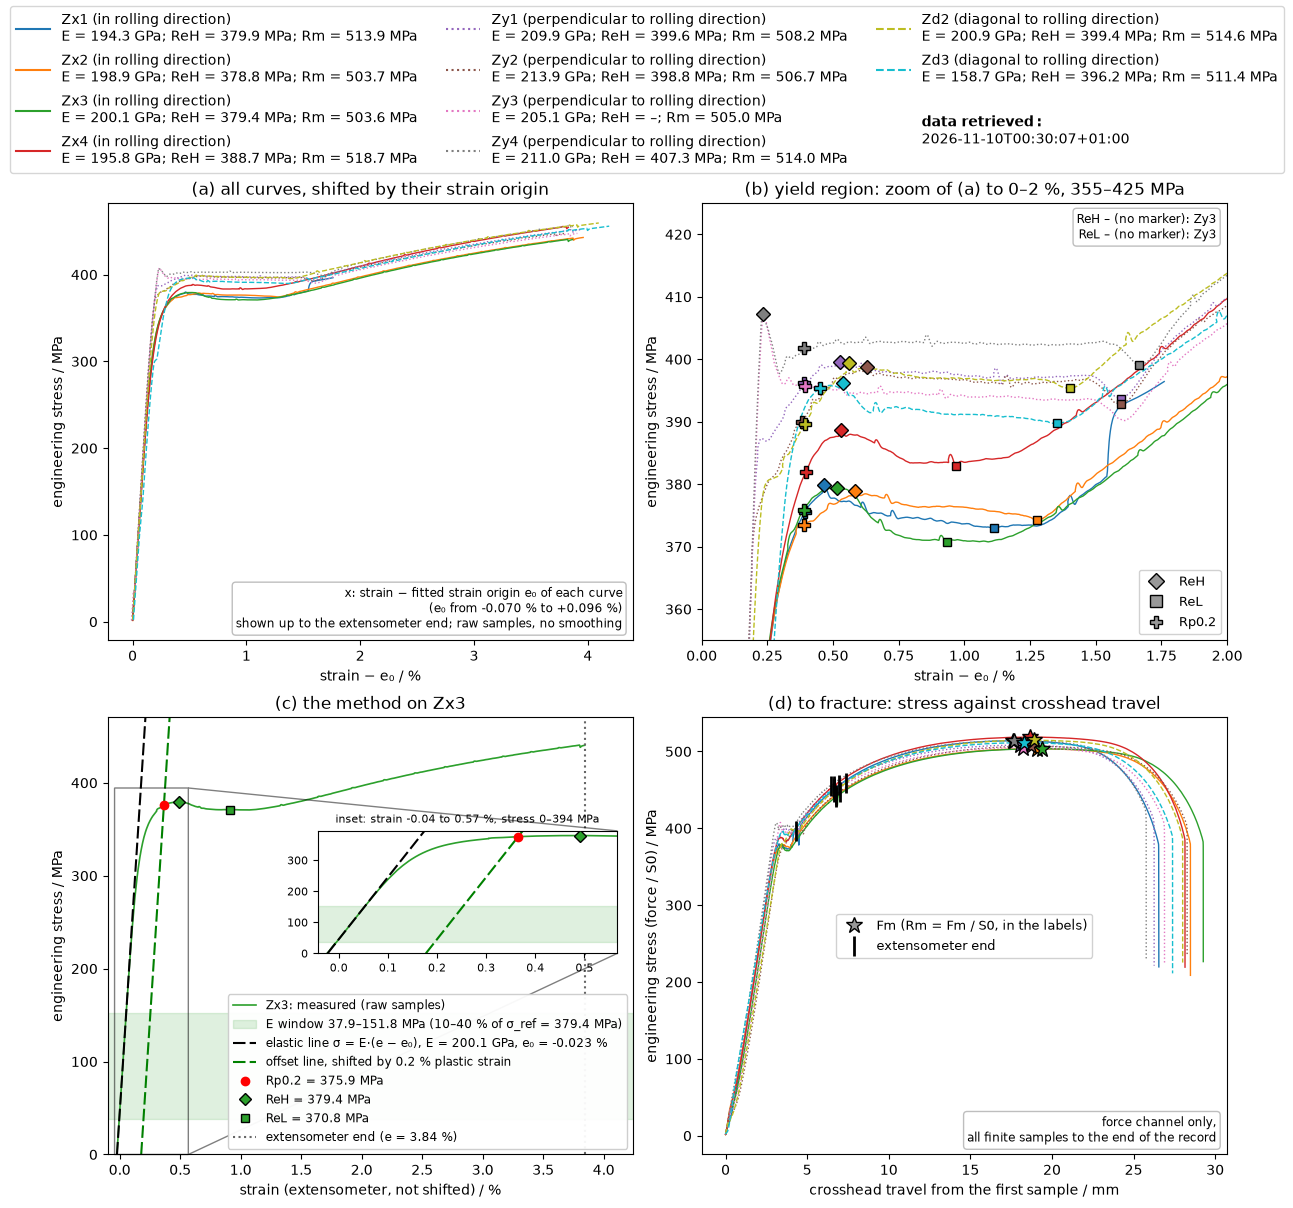

In [10]:
fig = demo.curves_overview_figure(result, retrieved=retrieved)

**Results.** (e) Computed minus lab value per specimen and quantity, in units of the tolerance, so the green band is `within`. (f) ReH against Rm. (g) E against Rp0.2, with the E range over the fit-window grid as bars. (h) Mean ± sd per orientation, with each specimen and its S0-based uncertainty (k = 1), not combined.

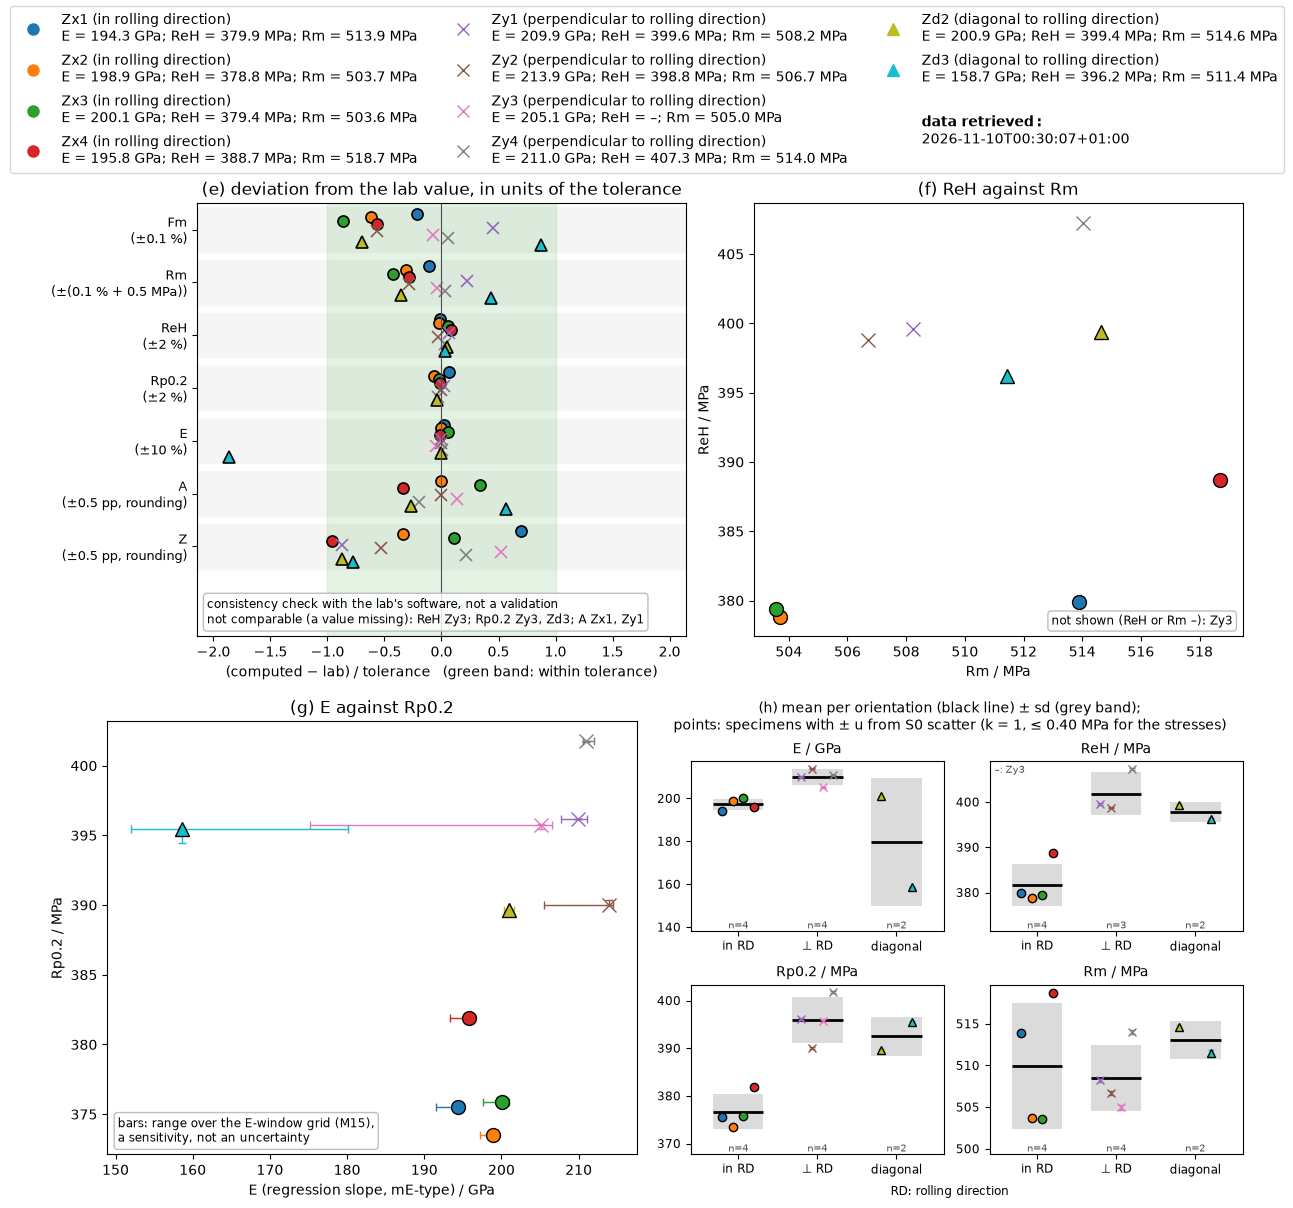

In [11]:
fig = demo.results_overview_figure(result, retrieved=retrieved)

## 8. Limitations

- **ISO-inspired, not conformant.** All properties are method-defined, ISO 6892-1-inspired. Nothing here claims conformity with ISO 6892-1 or its Annex G, or certifies the material.
- **Extensometer, Ag and Agt.** On all ten records the strain column ends at about 1.9 % (Zx1), 3.9 % (Zx2–Zx4, Zy1–Zy4) or 4.2 % (Zd2, Zd3), at a pause in the test. The method's extensometer end lies up to one 0.1 mm crosshead window before the last recorded strain (table below). The lab notes record removal of the extensometer after 3.9 % strain only for Zx2, Zx3 and Zx4; for the other seven, removal is our inference, not a statement of the graphs. The force maximum lies far beyond the extensometer end on every specimen, so **Ag and Agt are NaN on all ten**, with the flag `extensometer_invalid`, and are not estimated from the crosshead.
- **E is not a material modulus.** It is the regression slope of the elastic part (mE-type), not Annex-G-conformant. The extensometer class is unknown, which alone allows slope errors of about 10 %.
- **Zd3: E is `outside`; its elastic part is not straight.** The computed 158.7 GPa (lab 195 GPa, −18.6 %) is reported as the method gives it, but it should not be read as a modulus. The curvature shows in R² = 0.9954, in `e_linearity_rel_diff` = −0.14 and in a window range of 152–180 GPa that does not contain the lab value. No flag marks this, because the method has no rule for it. The cause of the curvature is unknown: settling or slip of the extensometer or grips, bending and local deformation all remain possible. How the lab obtained 195 GPa is also unknown.
- **Zy3: a real yield peak is missed.** The curve has a clear stress maximum of 407.6 MPa at 0.20 % strain (extensometer strain, not shifted), and the lab reports ReH 408 MPa, yet the method reports continuous yielding. A low-load event (the force falls by about 21 % within 0.07 s at about 34 MPa while the crosshead keeps moving; from the raw curve, not shown) lies inside the provisional fit window and raises the noise level to 4.9 MPa, against 0.08–0.48 MPa on eight other specimens and 1.1 MPa on Zd3 (table below), so the required drop (24.4 MPa) exceeds the 17.5 MPa that occurs before the extensometer end (both shown in notebook 02, section 3). ReH and ReL are NaN, and the flag `reh:extensometer_invalid` does not name this cause. The reported Rp0.2 (395.8 MPa) is a plateau stress, although the flag `in_yield_plateau` is missing. The result is reported as the approved method gives it, because changing the method after seeing this comparison would make a new agreement with the lab uninformative. The noise level is the residual scatter of the provisional fit, so it also picks up anything else that bends the curve in that window. The weakness is therefore not specific to Zy3: Zy2 has a similar event at about 26 MPa, at the edge of its fit window (from the raw curve, not shown), and Zd3's curved elastic part raises its noise level to 1.1 MPa, so it passes the yield test only narrowly (drop 6.5 MPa, required 5.5 MPa).
- **Further weak points**, found on synthetic curves:
  - a noisy plateau without an upper peak can be classified as discontinuous (a spurious ReH);
  - for a record whose stress never returns to ReH, the evaluation removes an abrupt final drop but not a gradual one: necking to 80 % of Rm before fracture gives ReL 316 instead of 379 MPa, and Fm NaN. Every result from this case carries the flag `fm:no_return_to_reh`; the line below names any specimen here with that flag;
  - ReL on a smoothly rising plateau: the plateau level is a median, so the recovery falls mid-plateau. Without noise, ReL becomes the transient minimum (flag `single_minimum`); with noise, it is about the plateau level minus the noise extreme. ReL is not compared with lab values.
- **Lab values are not ground truth**, and **the uncertainty is partial** (section 4).

Notebook 02 shows the Zy3 and Zd3 cases step by step.

In [12]:
no_return = results.index[results["flags"].str.contains("fm:no_return_to_reh")]
print("Stress never returns to ReH (fm:no_return_to_reh):", ", ".join(no_return) or "no specimen")

# The diagnostics cited above, from the run's own curve analyses.
display(pd.DataFrame({
    sid: {
        "noise level s_n / MPa": curve_analysis.noise_mpa,
        "R² of the E fit": curve_analysis.e_r2,
        "largest valid strain (method's extensometer end) / %": 100 * curve_analysis.extensometer_max_valid_strain,
        "last recorded strain / %": 100 * pd.Series(result.curves[sid].strain).dropna().iloc[-1],
    }
    for sid, curve_analysis in result.curve_analyses.items()
}).T)

Stress never returns to ReH (fm:no_return_to_reh): no specimen


,noise level s_n / MPa,R² of the E fit,largest valid strain (method's extensometer end) / %,last recorded strain / %
Zd2,0.1772,1.0000,4.1919,4.2044
Zd3,1.1025,0.9954,4.1968,4.2056
Zx1,0.3141,1.0000,1.8186,1.9253
Zx2,0.0849,1.0000,3.8890,3.9040
Zx3,0.4802,1.0000,3.8429,3.9052
Zx4,0.0840,1.0000,3.8205,3.9036
Zy1,0.1314,1.0000,3.8873,3.9076
Zy2,0.1941,1.0000,3.8951,3.9119
Zy3,4.8750,1.0000,3.8708,3.9060
Zy4,0.1046,1.0000,3.8231,3.9035


## Summary

- The same workflow analysed all ten specimens from the PMDco 2 and the PMDco 3 graphs; with identical curve bytes, every value, flag and comparison is identical (section 3).
- E, ReH, Rp0.2, Fm and Rm are defined on all specimens except Zy3's ReH and ReL, which the method misses (section 8); Ag and Agt are undefined on all ten because the strain record ends early (sections 4 and 8).
- The comparison with the lab values is a consistency check; Zd3's E is `outside` and Zy3's ReH is `not_comparable` (section 6).

Where to continue: [01](01-tensile-data-from-graphs.ipynb) for the graphs and the profiles, [02](02-tensile-analysis-nodes.ipynb) for the analysis steps, [03](03-tensile-workflow-building.ipynb) for the workflow construction, [04](04-tensile-workflow-knowledge-graph.ipynb) for the run as a knowledge graph.